# code_164 · Shared mechanical tasks and bounded target adaptation

**Book:** section 31.4. A self-contained limited-label learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_31_GUIDE.md), [run evidence](../CHAPTER_31_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_164).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=4264;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 4264


<a id="multitask-loss-and-transfer"></a>
 ## Sharing changes gradients, capacity and supervision
 Generate 180 source buildings,40 source-development buildings and 60 familiar final buildings, two load cases per building. Each has load, span, flexural rigidity and two generated condition indicators. Deflection follows a stated simply supported midpoint-load formula with small observation noise; damage is a separate constructed binary mechanism. Compare independent small networks, a shared two-head network trained with raw squared deflection error plus binary loss, and the same shared network with source-standardized deflection targets. Every method sees the same 360 source records and both target types. A fixed standardized development objective chooses each checkpoint from 1200 offered Adam updates. New-material target data separately supply 24 calibration,16 development and 60 final buildings. Head-only and rank-one feature adaptations use 4 or 16 calibration buildings and 200 offered updates; the new-material development group selects checkpoints, never the final groups.


,method,domain,deflection_MAE_mm,damage_accuracy,damage_Brier,source_records,parameters
0,Separate scaled,Familiar,0.473949,0.941667,0.032387,360,178
1,Separate scaled,Changed material,1.042694,0.583333,0.357945,360,178
2,Shared raw,Familiar,0.264267,0.958333,0.035567,360,94
3,Shared raw,Changed material,0.419637,0.591667,0.372638,360,94
4,Shared scaled,Familiar,0.552078,0.958333,0.034553,360,94
5,Shared scaled,Changed material,0.770615,0.583333,0.405694,360,94


,method,domain,deflection_MAE_mm,damage_accuracy,damage_Brier,target_calibration_buildings,target_records,target_scalar_outcomes,target_development_records,target_development_scalar_outcomes,selected_update,trainable_parameters
0,Head-only,Changed material,0.855667,0.600000,0.371402,4,8,16,32,64,200,10
1,Rank-one adapter,Changed material,1.138370,0.458333,0.330255,4,8,16,32,64,100,18
2,Head-only,Changed material,0.872907,0.600000,0.371431,16,32,64,32,64,200,10
3,Rank-one adapter,Changed material,0.880087,0.600000,0.234438,16,32,64,32,64,150,18


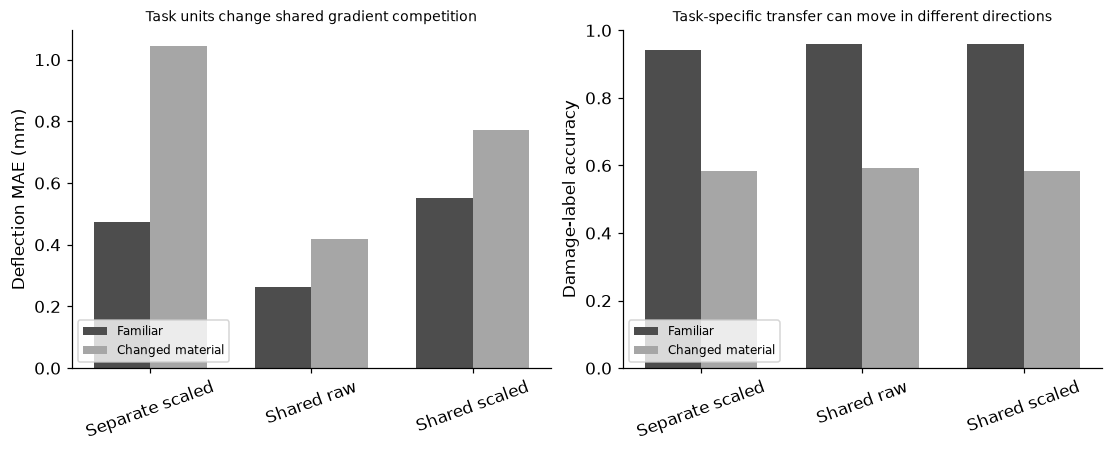

In [2]:
from sklearn.preprocessing import StandardScaler
def material_cohort(n,offset,changed=False):
    g=np.repeat(np.arange(offset,offset+n),2);building=rng.normal(0,.12,n);load=rng.uniform(1,10,2*n);span=np.repeat(rng.uniform(2,7,n),2);rigidity=np.repeat(rng.uniform(1,6,n),2);condition=np.repeat(rng.normal(0,1,n),2)+rng.normal(0,.1,2*n);indicator=rng.normal(0,1,2*n);raw=np.column_stack([load,span,rigidity,condition,indicator]);true_deflection=(1000*load)*span**3/(48*1e6*rigidity)*1000;deflection=true_deflection+rng.normal(0,.15,2*n);latent=condition+.35*load-.8*indicator+np.repeat(building,2)-2.0
    if changed:latent=-condition+.35*load-.8*indicator+np.repeat(building,2)-1.2
    damage=(latent+rng.normal(0,.15,2*n)>0).astype(float);return raw,deflection,damage,g
sx,sd,sy,sg=material_cohort(180,0);dx,dd,dy,dg=material_cohort(40,1000);fx,fd,fy,fg=material_cohort(60,2000);cx,cd,cy,cg=material_cohort(24,3000,True);tx,td,ty,tg=material_cohort(16,4000,True);nx,nd,ny,ng=material_cohort(60,5000,True);assert len(set(np.r_[sg,dg,fg,cg,tg,ng]))==380
scaler=StandardScaler().fit(sx);mean=float(sd.mean());scale=float(sd.std());S=torch.tensor(scaler.transform(sx));D=torch.tensor(scaler.transform(dx));F=torch.tensor(scaler.transform(fx));C=torch.tensor(scaler.transform(cx));T=torch.tensor(scaler.transform(tx));N=torch.tensor(scaler.transform(nx));sd_t=torch.tensor(sd);sy_t=torch.tensor(sy)
class Shared(nn.Module):
    def __init__(self):super().__init__();self.trunk=nn.Sequential(nn.Linear(5,8),nn.Tanh(),nn.Linear(8,4),nn.Tanh());self.reg=nn.Linear(4,1);self.binary=nn.Linear(4,1)
    def forward(self,x):h=self.trunk(x);return self.reg(h).squeeze(-1),self.binary(h).squeeze(-1)
class Separate(nn.Module):
    def __init__(self):super().__init__();self.reg=nn.Sequential(nn.Linear(5,8),nn.Tanh(),nn.Linear(8,4),nn.Tanh(),nn.Linear(4,1));self.binary=copy.deepcopy(self.reg)
    def forward(self,x):return self.reg(x).squeeze(-1),self.binary(x).squeeze(-1)
def standardized_objective(model,x,d,y,raw_output=False):
    a,b=model(x);prediction=(a-mean)/scale if raw_output else a;return nn.functional.mse_loss(prediction,torch.tensor((d-mean)/scale))+nn.functional.binary_cross_entropy_with_logits(b,torch.tensor(y))
models={};traces={};selected={};rows=[]
for name in ['Separate scaled','Shared raw','Shared scaled']:
    torch.manual_seed(SEED);model=Separate() if name.startswith('Separate') else Shared();optimizer=torch.optim.Adam(model.parameters(),lr=.01);raw_output=name=='Shared raw';best=np.inf;trace=[]
    for step in range(1200):
        a,b=model(S);target=sd_t if raw_output else (sd_t-mean)/scale;loss=nn.functional.mse_loss(a,target)+nn.functional.binary_cross_entropy_with_logits(b,sy_t);optimizer.zero_grad();loss.backward();optimizer.step()
        if (step+1)%100==0:
            with torch.no_grad():score=float(standardized_objective(model,D,dd,dy,raw_output))
            trace.append((step+1,score))
            if score<best:best=score;state=copy.deepcopy(model.state_dict());selected[name]=step+1
    model.load_state_dict(state);model.eval();models[name]=(model,raw_output);traces[name]=trace
def assess(name,model,x,d,y,domain,raw_output=False,**extra):
    with torch.no_grad():a,b=model(x);prediction=a.numpy() if raw_output else a.numpy()*scale+mean;p=b.sigmoid().numpy()
    return dict(method=name,domain=domain,deflection_MAE_mm=float(np.mean(np.abs(prediction-d))),damage_accuracy=float(np.mean((p>=.5)==y)),damage_Brier=float(np.mean((p-y)**2)),**extra)
for name,(model,raw_output) in models.items():
    for domain,x,d,y in [('Familiar',F,fd,fy),('Changed material',N,nd,ny)]:rows.append(assess(name,model,x,d,y,domain,raw_output,source_records=360,parameters=sum(p.numel() for p in model.parameters())))
source_model=models['Shared scaled'][0];before=hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in source_model.parameters())).hexdigest();adapt_rows=[]
class RankOne(nn.Module):
    def __init__(self,base):
        super().__init__();self.base=copy.deepcopy(base)
        for p in self.base.trunk.parameters():p.requires_grad=False
        self.A=nn.Parameter(torch.randn(4,1)*.02);self.B=nn.Parameter(torch.zeros(1,4))
    def forward(self,x):h=self.base.trunk(x);h=h+h@self.A@self.B;return self.base.reg(h).squeeze(-1),self.base.binary(h).squeeze(-1)
for budget in [4,16]:
    ids=np.flatnonzero(cg<3000+budget);assert len(ids)==2*budget
    for kind in ['Head-only','Rank-one adapter']:
        torch.manual_seed(SEED);model=copy.deepcopy(source_model) if kind=='Head-only' else RankOne(source_model)
        if kind=='Head-only':
            for p in model.trunk.parameters():p.requires_grad=False
        optimizer=torch.optim.Adam([p for p in model.parameters() if p.requires_grad],lr=.005);best=np.inf
        for step in range(200):
            loss=standardized_objective(model,C[ids],cd[ids],cy[ids]);optimizer.zero_grad();loss.backward();optimizer.step()
            if (step+1)%50==0:
                with torch.no_grad():score=float(standardized_objective(model,T,td,ty))
                if score<best:best=score;state=copy.deepcopy(model.state_dict());selected_step=step+1
        model.load_state_dict(state);model.eval();adapt_rows.append(assess(kind,model,N,nd,ny,'Changed material',False,target_calibration_buildings=budget,target_records=2*budget,target_scalar_outcomes=4*budget,target_development_records=32,target_development_scalar_outcomes=64,selected_update=selected_step,trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad)))
assert before==hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in source_model.parameters())).hexdigest()
RESULTS.update(source_buildings=180,source_records=360,source_development_buildings=40,source_development_scalar_outcomes=160,familiar_final_buildings=60,changed_final_buildings=60,source_updates_offered=1200,source_selected_updates=selected,source_target_mean_mm=mean,source_target_scale_mm=scale,source_metrics=rows,target_adaptation_metrics=adapt_rows,frozen_source_unchanged=True,final_labels_used_for_selection=0);display(pd.DataFrame(rows));display(pd.DataFrame(adapt_rows))
fig,axes=plt.subplots(1,2,figsize=(10,4));names=['Separate scaled','Shared raw','Shared scaled'];xx=np.arange(3)
for i,domain in enumerate(['Familiar','Changed material']):
    rr=[r for r in rows if r['domain']==domain];axes[0].bar(xx+(i-.5)*.35,[r['deflection_MAE_mm'] for r in rr],width=.35,color=['.3','.65'][i],label=domain);axes[1].bar(xx+(i-.5)*.35,[r['damage_accuracy'] for r in rr],width=.35,color=['.3','.65'][i],label=domain)
axes[0].set(xticks=xx,xticklabels=names,ylabel='Deflection MAE (mm)',title='Task units change shared gradient competition');axes[1].set(xticks=xx,xticklabels=names,ylim=(0,1),ylabel='Damage-label accuracy',title='Task-specific transfer can move in different directions')
for ax in axes:ax.tick_params(axis='x',rotation=20);ax.legend(fontsize=8,loc='lower left')
plt.show()


<a id="bounded-parameter-adaptation"></a>
 ## A small adapter still consumes target labels and selection evidence
 Head-only fitting changes two output heads; a rank-one feature adapter additionally changes an eight-parameter residual map after the frozen shared trunk. The latter is an explicit low-rank teaching mechanism, not a named PEFT implementation or attention-LoRA claim. Both use the same source scaling and each source record carries two outcomes. Target support budgets count whole buildings; two cases and two scalar outcomes per case mean four target outcomes per building. The 32 target-development records contribute 64 additional selection outcomes at every budget. Changed material here changes the damage mechanism while preserving the deflection formula, so transfer effects differ by task. The frozen source model is byte-hash checked after adaptation of copies.


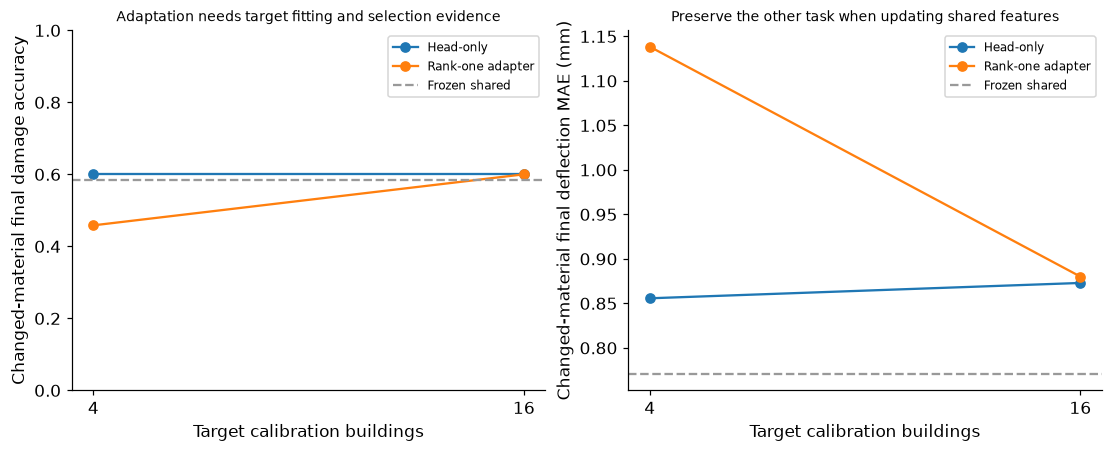

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for kind in ['Head-only','Rank-one adapter']:
    rr=[r for r in adapt_rows if r['method']==kind];axes[0].plot([r['target_calibration_buildings'] for r in rr],[r['damage_accuracy'] for r in rr],marker='o',label=kind);axes[1].plot([r['target_calibration_buildings'] for r in rr],[r['deflection_MAE_mm'] for r in rr],marker='o',label=kind)
frozen=next(r for r in rows if r['method']=='Shared scaled' and r['domain']=='Changed material');axes[0].axhline(frozen['damage_accuracy'],color='.6',linestyle='--',label='Frozen shared');axes[1].axhline(frozen['deflection_MAE_mm'],color='.6',linestyle='--',label='Frozen shared');axes[0].set(xticks=[4,16],xlabel='Target calibration buildings',ylabel='Changed-material final damage accuracy',ylim=(0,1),title='Adaptation needs target fitting and selection evidence');axes[1].set(xticks=[4,16],xlabel='Target calibration buildings',ylabel='Changed-material final deflection MAE (mm)',title='Preserve the other task when updating shared features')
for ax in axes:ax.legend(fontsize=8)
plt.show()
assert len(rows)==6 and len(adapt_rows)==4 and all(r['trainable_parameters'] in [10,18] for r in adapt_rows)


In [4]:
summary={'example_id':'code_164','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual shared-trunk and separate-model training on two mechanical teaching targets', 'raw versus source-scaled joint losses and task-specific assessment', 'source-family and changed-material whole-building evaluation', 'actual head-only and rank-one feature adaptation with frozen-backbone hashes', 'target fitting labels and target development outcomes counted separately'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual shared-trunk and separate-model training on two mechanical teaching targets", "raw versus source-scaled joint losses and task-specific assessment", "source-family and changed-material whole-building evaluation", "actual head-only and rank-one feature adaptation with frozen-backbone hashes", "target fitting labels and target development outcomes counted separately"], "elapsed_seconds": 1.718, "example_id": "code_164", "hardware": "Darwin arm64 CPU", "results": {"changed_final_buildings": 60, "familiar_final_buildings": 60, "final_labels_used_for_selection": 0, "frozen_source_unchanged": true, "source_buildings": 180, "source_development_buildings": 40, "source_development_scalar_outcomes": 160, "source_metrics": [{"damage_Brier": 0.03238728017278983, "damage_accuracy": 0.9416666666666667, "deflection_MAE_mm": 0.47394868949956287, "domain": "Familiar", "method": "Separate scaled", "parameters": 178, "source_records": 360}, {"damag